<a href="https://colab.research.google.com/github/abrarjahinzihan/Mushroom_Classification/blob/main/Mushroom_Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#  Mushroom Classification: Edible vs Poisonous
**Goal:** Classify wild mushrooms as *edible* or *poisonous* from physical characteristics (cap shape, surface, color, gill spacing, veil type, odor, ...) using **Decision Tree** and **Random Forest** classifiers, with **100% sensitivity (recall) for the poisonous class** — i.e. no poisonous mushroom is ever labelled edible.

**Dataset:** UCI Mushroom dataset (8,124 samples, 22 categorical features + class).

**Notebook outline**
1. Setup & load data (Google Drive)
2. Exploratory data analysis
3. Preprocessing
4. Decision Tree
5. Random Forest
6. Sensitivity verification (hold-out, multiple seeds, 5-fold CV)
7. Feature importance & decision rules
8. Model comparison & conclusion

## 1. Setup & load data

In [ ]:
# Mount Google Drive and set the dataset path
from google.colab import drive
drive.mount('/content/drive')



Mounted at /content/drive


In [ ]:
# >>> EDIT THIS PATH to where you uploaded mushrooms.csv in your Drive <<<
DATA_PATH = '/content/drive/MyDrive/Untitled Folder 2/mushrooms.csv'

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict, GridSearchCV
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report, ConfusionMatrixDisplay)

sns.set_style('whitegrid')
RANDOM_STATE = 42

df = pd.read_csv(DATA_PATH)
print('Shape:', df.shape)
df.head()

Shape: (8124, 23)


,class,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,...,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
0,p,x,s,n,t,p,f,c,n,k,...,s,w,w,p,w,o,p,k,s,u
1,e,x,s,y,t,a,f,c,b,k,...,s,w,w,p,w,o,p,n,n,g
2,e,b,s,w,t,l,f,c,b,n,...,s,w,w,p,w,o,p,n,n,m
3,p,x,y,w,t,p,f,c,n,n,...,s,w,w,p,w,o,p,k,s,u
4,e,x,s,g,f,n,f,w,b,k,...,s,w,w,p,w,o,e,n,a,g


## 2. Exploratory data analysis

In [ ]:
print('Missing values:', df.isna().sum().sum())
print('Duplicate rows:', df.duplicated().sum())
print()
df.info()

Missing values: 0
Duplicate rows: 0

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8124 entries, 0 to 8123
Data columns (total 23 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   class                     8124 non-null   object
 1   cap-shape                 8124 non-null   object
 2   cap-surface               8124 non-null   object
 3   cap-color                 8124 non-null   object
 4   bruises                   8124 non-null   object
 5   odor                      8124 non-null   object
 6   gill-attachment           8124 non-null   object
 7   gill-spacing              8124 non-null   object
 8   gill-size                 8124 non-null   object
 9   gill-color                8124 non-null   object
 10  stalk-shape               8124 non-null   object
 11  stalk-root                8124 non-null   object
 12  stalk-surface-above-ring  8124 non-null   object
 13  stalk-surface-below-ring  8124 non-null  

class
Edible       4208
Poisonous    3916
Name: count, dtype: int64


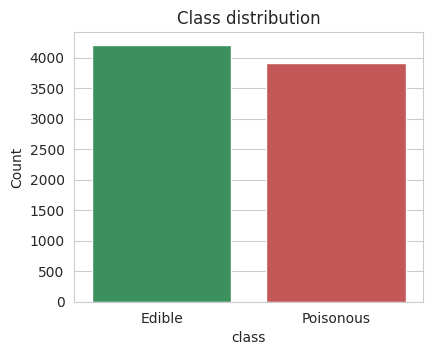

In [ ]:
# Class balance (e = edible, p = poisonous)
counts = df['class'].map({'e': 'Edible', 'p': 'Poisonous'}).value_counts()
print(counts)
plt.figure(figsize=(4.5, 3.5))
sns.barplot(x=counts.index, y=counts.values, hue=counts.index, palette=['#2e9e5b', '#d64545'], legend=False)
plt.title('Class distribution'); plt.ylabel('Count')
plt.show()

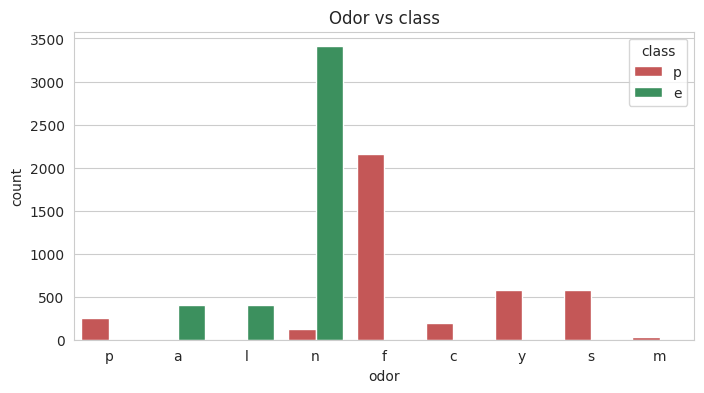

In [ ]:
# Odor is the strongest single predictor - look at class split per odor
# (n=none, a=almond, l=anise, c=creosote, f=foul, m=musty, p=pungent, s=spicy, y=fishy)
plt.figure(figsize=(8, 4))
sns.countplot(data=df, x='odor', hue='class', palette={'e': '#2e9e5b', 'p': '#d64545'})
plt.title('Odor vs class')
plt.show()

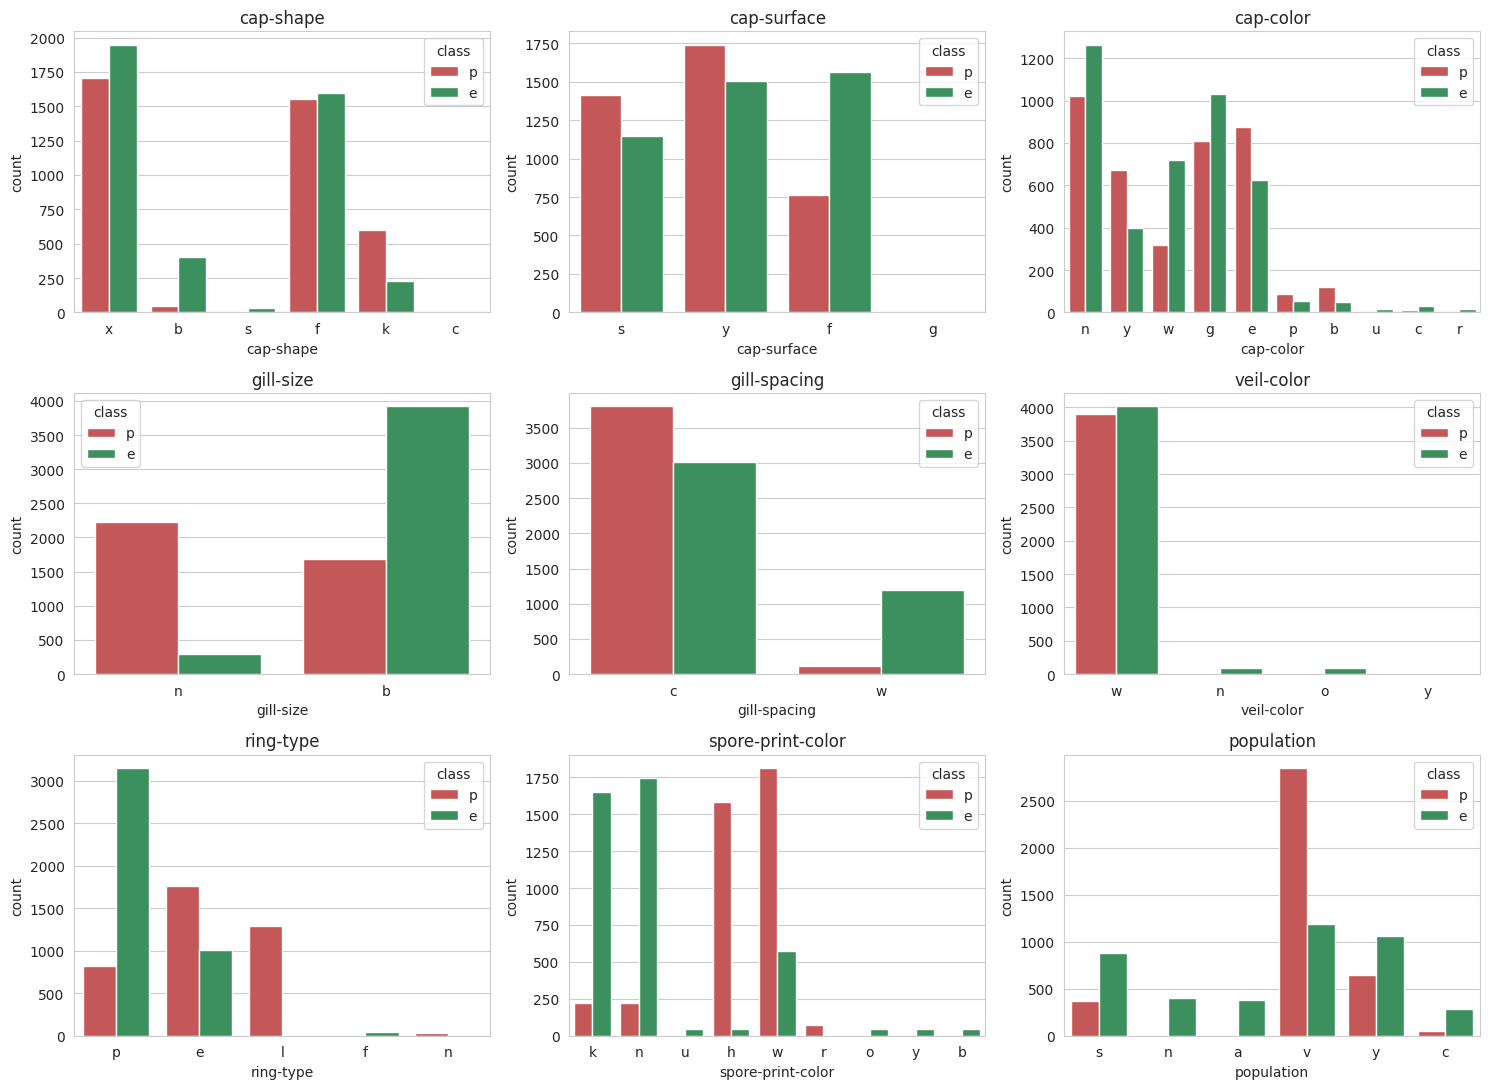

In [ ]:
# Class split for several other key features
feats = ['cap-shape', 'cap-surface', 'cap-color', 'gill-size', 'gill-spacing', 'veil-color',
         'ring-type', 'spore-print-color', 'population']
fig, axes = plt.subplots(3, 3, figsize=(15, 11))
for ax, f in zip(axes.ravel(), feats):
    sns.countplot(data=df, x=f, hue='class', palette={'e': '#2e9e5b', 'p': '#d64545'}, ax=ax)
    ax.set_title(f)
plt.tight_layout(); plt.show()

In [ ]:
# Features with a single value carry no information (e.g. veil-type)
for c in df.columns:
    if df[c].nunique() == 1:
        print(f'Constant column: {c} -> {df[c].unique()}')

Constant column: veil-type -> ['p']


## 3. Preprocessing
All features are categorical, so we one-hot encode them. The target is encoded as **1 = poisonous (positive class)**, **0 = edible**, so `recall` on class 1 is exactly the *sensitivity for poisonous specimens*.
We use a **stratified 80/20 split**.

In [ ]:
y = (df['class'] == 'p').astype(int)                    # 1 = poisonous (positive class)
X = pd.get_dummies(df.drop(columns='class'), dtype=int)  # one-hot encode categorical features
print('Feature matrix:', X.shape)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print('Train:', X_train.shape, ' Test:', X_test.shape)
print('Poisonous in test set:', y_test.sum())

Feature matrix: (8124, 117)
Train: (6499, 117)  Test: (1625, 117)
Poisonous in test set: 783


In [ ]:
def evaluate(model, X_te, y_te, name):
    pred = model.predict(X_te)
    tn, fp, fn, tp = confusion_matrix(y_te, pred).ravel()
    res = {
        'Model': name,
        'Accuracy': accuracy_score(y_te, pred),
        'Precision (poisonous)': precision_score(y_te, pred),
        'Sensitivity / Recall (poisonous)': recall_score(y_te, pred),
        'Specificity (edible)': tn / (tn + fp),
        'F1 (poisonous)': f1_score(y_te, pred),
        'False negatives (poisonous called edible)': fn,
    }
    print(f'===== {name} =====')
    print(classification_report(y_te, pred, target_names=['Edible', 'Poisonous'], digits=4))
    ConfusionMatrixDisplay(confusion_matrix(y_te, pred), display_labels=['Edible', 'Poisonous']).plot(cmap='Blues')
    plt.title(f'{name} - confusion matrix'); plt.show()
    return res

## 4. Decision Tree
To protect against the dangerous error (a poisonous mushroom predicted edible), we penalise false negatives with `class_weight={0:1, 1:5}`.

===== Decision Tree =====
              precision    recall  f1-score   support

      Edible     1.0000    1.0000    1.0000       842
   Poisonous     1.0000    1.0000    1.0000       783

    accuracy                         1.0000      1625
   macro avg     1.0000    1.0000    1.0000      1625
weighted avg     1.0000    1.0000    1.0000      1625



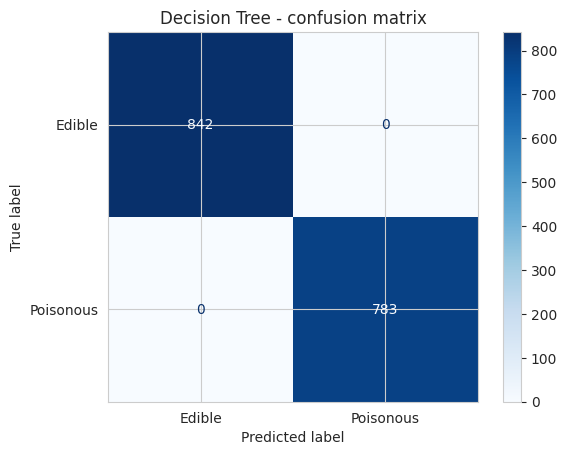

Tree depth: 7 | leaves: 11


In [ ]:
dt = DecisionTreeClassifier(class_weight={0: 1, 1: 5}, random_state=RANDOM_STATE)
dt.fit(X_train, y_train)
dt_res = evaluate(dt, X_test, y_test, 'Decision Tree')
print('Tree depth:', dt.get_depth(), '| leaves:', dt.get_n_leaves())

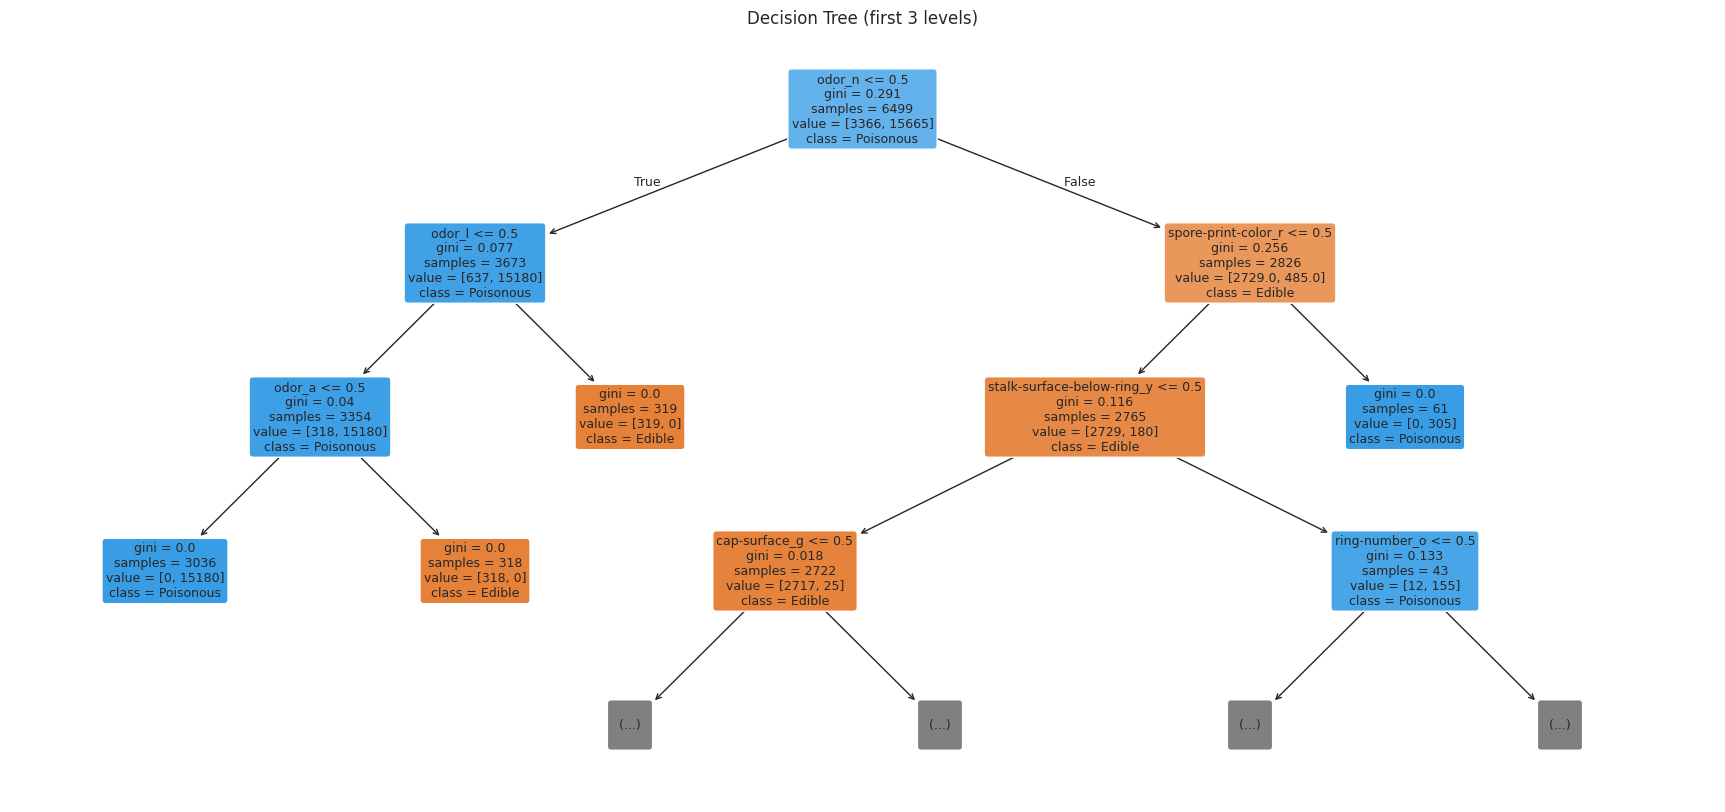

In [ ]:
# Visualise the (top of the) tree
plt.figure(figsize=(22, 10))
plot_tree(dt, feature_names=X.columns, class_names=['Edible', 'Poisonous'],
          filled=True, rounded=True, max_depth=3, fontsize=9)
plt.title('Decision Tree (first 3 levels)'); plt.show()

## 5. Random Forest

===== Random Forest =====
              precision    recall  f1-score   support

      Edible     1.0000    1.0000    1.0000       842
   Poisonous     1.0000    1.0000    1.0000       783

    accuracy                         1.0000      1625
   macro avg     1.0000    1.0000    1.0000      1625
weighted avg     1.0000    1.0000    1.0000      1625



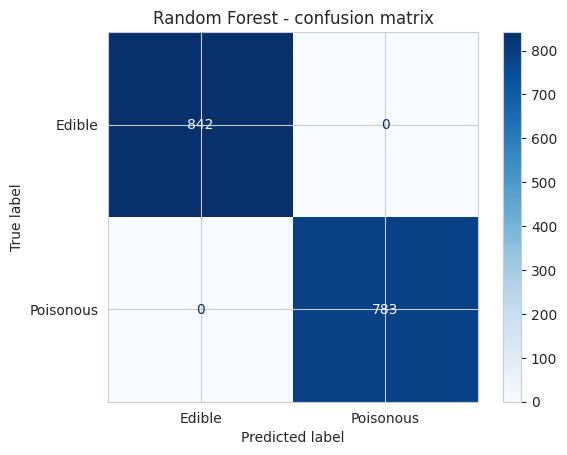

In [ ]:
rf = RandomForestClassifier(n_estimators=200, class_weight={0: 1, 1: 5},
                            random_state=RANDOM_STATE, n_jobs=-1)
rf.fit(X_train, y_train)
rf_res = evaluate(rf, X_test, y_test, 'Random Forest')

## 6. Sensitivity verification
A single split can be lucky, so we verify the **100% poisonous-class sensitivity** target in three ways:
1. Repeated hold-out over several random seeds
2. Stratified 5-fold cross-validation (every one of the 8,124 mushrooms is predicted while unseen)

In [ ]:
rows = []
for seed in [1, 7, 42, 123, 2024]:
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, stratify=y, random_state=seed)
    for name, m in [('Decision Tree', DecisionTreeClassifier(class_weight={0: 1, 1: 5}, random_state=seed)),
                    ('Random Forest', RandomForestClassifier(n_estimators=200, class_weight={0: 1, 1: 5},
                                                             random_state=seed, n_jobs=-1))]:
        m.fit(Xtr, ytr); p = m.predict(Xte)
        rows.append({'seed': seed, 'model': name,
                     'accuracy': accuracy_score(yte, p),
                     'poisonous_sensitivity': recall_score(yte, p),
                     'missed_poisonous': int(((yte == 1) & (p == 0)).sum())})
seed_df = pd.DataFrame(rows)
seed_df

,seed,model,accuracy,poisonous_sensitivity,missed_poisonous
0,1,Decision Tree,1.0,1.0,0
1,1,Random Forest,1.0,1.0,0
2,7,Decision Tree,1.0,1.0,0
3,7,Random Forest,1.0,1.0,0
4,42,Decision Tree,1.0,1.0,0
5,42,Random Forest,1.0,1.0,0
6,123,Decision Tree,1.0,1.0,0
7,123,Random Forest,1.0,1.0,0
8,2024,Decision Tree,1.0,1.0,0
9,2024,Random Forest,1.0,1.0,0


In [ ]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_rows = []
for name, m in [('Decision Tree', DecisionTreeClassifier(class_weight={0: 1, 1: 5}, random_state=RANDOM_STATE)),
                ('Random Forest', RandomForestClassifier(n_estimators=200, class_weight={0: 1, 1: 5},
                                                         random_state=RANDOM_STATE, n_jobs=-1))]:
    p = cross_val_predict(m, X, y, cv=skf)
    tn, fp, fn, tp = confusion_matrix(y, p).ravel()
    cv_rows.append({'model': name, 'accuracy': accuracy_score(y, p),
                    'poisonous_sensitivity': recall_score(y, p),
                    'poisonous_caught': tp, 'poisonous_missed': fn})
cv_df = pd.DataFrame(cv_rows)
display(cv_df)

TARGET_MET = (seed_df['poisonous_sensitivity'] == 1.0).all() and (cv_df['poisonous_sensitivity'] == 1.0).all()
print('\n100% poisonous-class sensitivity achieved on every split and in CV:', TARGET_MET)

,model,accuracy,poisonous_sensitivity,poisonous_caught,poisonous_missed
0,Decision Tree,1.0,1.0,3916,0
1,Random Forest,1.0,1.0,3916,0



100% poisonous-class sensitivity achieved on every split and in CV: True


## 7. Feature importance & interpretable rules

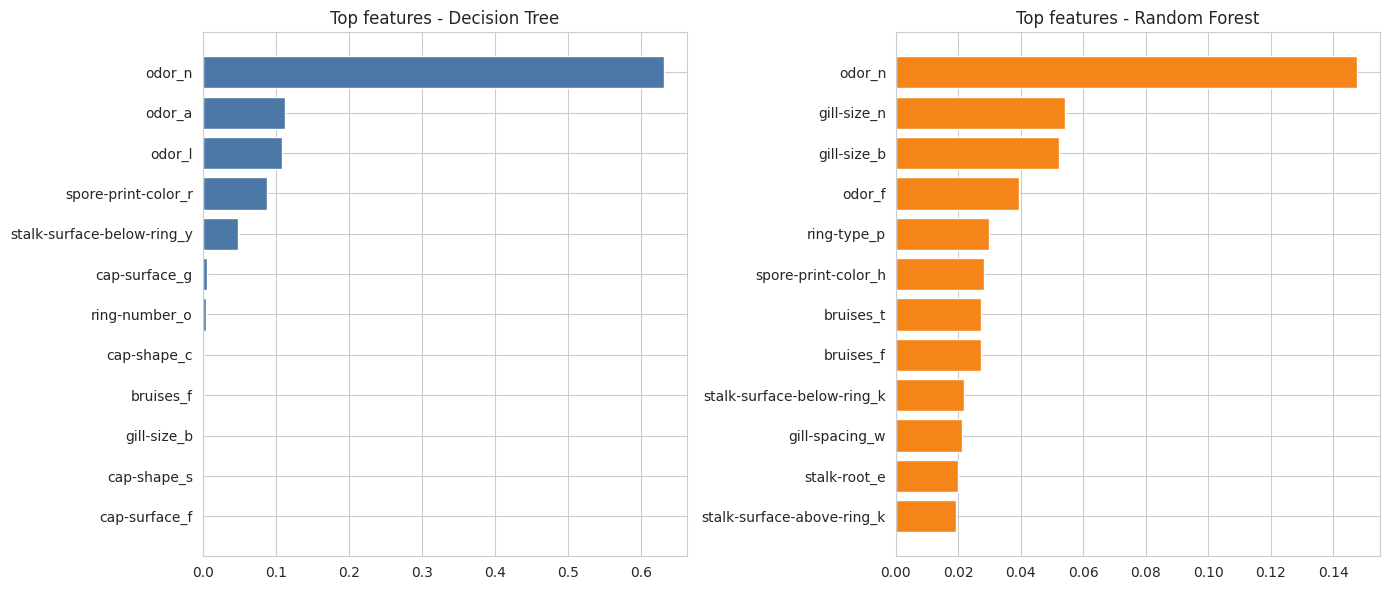

In [ ]:
imp = pd.DataFrame({'feature': X.columns,
                    'Decision Tree': dt.feature_importances_,
                    'Random Forest': rf.feature_importances_})
top = imp.sort_values('Random Forest', ascending=False).head(15)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, col, color in zip(axes, ['Decision Tree', 'Random Forest'], ['#4c78a8', '#f58518']):
    t = imp.sort_values(col, ascending=False).head(12)
    ax.barh(t['feature'][::-1], t[col][::-1], color=color)
    ax.set_title(f'Top features - {col}')
plt.tight_layout(); plt.show()

In [ ]:
# Human-readable rules from a shallow tree. NOTE: capping depth at 4 slightly lowers sensitivity (~99.7%),
# so the full-depth tree above is the one that meets the 100% target.
shallow = DecisionTreeClassifier(max_depth=4, class_weight={0: 1, 1: 5}, random_state=RANDOM_STATE).fit(X_train, y_train)
print(export_text(shallow, feature_names=list(X.columns)))
print('Shallow tree (depth 4) poisonous sensitivity:', recall_score(y_test, shallow.predict(X_test)))

|--- odor_n <= 0.50
|   |--- odor_l <= 0.50
|   |   |--- odor_a <= 0.50
|   |   |   |--- class: 1
|   |   |--- odor_a >  0.50
|   |   |   |--- class: 0
|   |--- odor_l >  0.50
|   |   |--- class: 0
|--- odor_n >  0.50
|   |--- spore-print-color_r <= 0.50
|   |   |--- stalk-surface-below-ring_y <= 0.50
|   |   |   |--- cap-surface_g <= 0.50
|   |   |   |   |--- class: 0
|   |   |   |--- cap-surface_g >  0.50
|   |   |   |   |--- class: 1
|   |   |--- stalk-surface-below-ring_y >  0.50
|   |   |   |--- stalk-root_b <= 0.50
|   |   |   |   |--- class: 1
|   |   |   |--- stalk-root_b >  0.50
|   |   |   |   |--- class: 0
|   |--- spore-print-color_r >  0.50
|   |   |--- class: 1

Shallow tree (depth 4) poisonous sensitivity: 0.9974457215836526


## 8. Hyperparameter tuning (optimised for poisonous recall)

In [ ]:
# Tune with recall of the poisonous class as the scoring metric
param_grid = {'max_depth': [None, 5, 10], 'min_samples_leaf': [1, 2, 5],
              'class_weight': [None, 'balanced', {0: 1, 1: 5}]}
gs_dt = GridSearchCV(DecisionTreeClassifier(random_state=RANDOM_STATE), param_grid,
                     scoring='recall', cv=5, n_jobs=-1).fit(X_train, y_train)

rf_grid = {'n_estimators': [100, 200], 'max_depth': [None, 10], 'class_weight': [None, {0: 1, 1: 5}]}
gs_rf = GridSearchCV(RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1), rf_grid,
                     scoring='recall', cv=5, n_jobs=-1).fit(X_train, y_train)

print('Best Decision Tree params:', gs_dt.best_params_, '| CV recall:', round(gs_dt.best_score_, 4))
print('Best Random Forest params:', gs_rf.best_params_, '| CV recall:', round(gs_rf.best_score_, 4))
for n, g in [('Tuned Decision Tree', gs_dt), ('Tuned Random Forest', gs_rf)]:
    print(n, 'test sensitivity:', recall_score(y_test, g.best_estimator_.predict(X_test)))

Best Decision Tree params: {'class_weight': {0: 1, 1: 5}, 'max_depth': None, 'min_samples_leaf': 2} | CV recall: 1.0
Best Random Forest params: {'class_weight': None, 'max_depth': None, 'n_estimators': 100} | CV recall: 1.0
Tuned Decision Tree test sensitivity: 1.0
Tuned Random Forest test sensitivity: 1.0


## 9. Save the model & predict new mushrooms

In [ ]:
import joblib, os
SAVE_DIR = '/content/drive/MyDrive/mushroom_project'
os.makedirs(SAVE_DIR, exist_ok=True)

# Final model: Random Forest trained on ALL data with the poisonous-weighted classes
final_model = RandomForestClassifier(n_estimators=200, class_weight={0: 1, 1: 5},
                                     random_state=RANDOM_STATE, n_jobs=-1).fit(X, y)
joblib.dump({'model': final_model, 'columns': list(X.columns)}, f'{SAVE_DIR}/mushroom_rf.joblib')
print('Saved to', SAVE_DIR)

Saved to /content/drive/MyDrive/mushroom_project


In [ ]:
def predict_mushroom(sample: dict, threshold: float = 0.5):
    """sample: raw categorical codes, e.g. {'odor': 'f', 'gill-size': 'n', ...}.
    Unspecified features are treated as unknown (all zero one-hot).
    Lower the threshold (e.g. 0.2) to be even more cautious: anything that is even
    slightly likely to be poisonous gets flagged."""
    row = pd.DataFrame(0, index=[0], columns=X.columns)
    for feat, val in sample.items():
        col = f'{feat}_{val}'
        if col in row.columns:
            row[col] = 1
    p = final_model.predict_proba(row)[0, 1]
    return ('POISONOUS - do not eat' if p >= threshold else 'edible'), round(float(p), 3)

# Demo on 6 real rows (3 edible, 3 poisonous) from the dataset (raw categorical values)
demo = pd.concat([df[df['class']=='e'].sample(3, random_state=3), df[df['class']=='p'].sample(3, random_state=3)])
for _, r in demo.iterrows():
    label, prob = predict_mushroom(r.drop('class').to_dict())
    print(f"actual={'poisonous' if r['class']=='p' else 'edible':9s} -> model: {label} (P(poisonous)={prob})")

actual=edible    -> model: edible (P(poisonous)=0.01)
actual=edible    -> model: edible (P(poisonous)=0.0)
actual=edible    -> model: edible (P(poisonous)=0.0)
actual=poisonous -> model: POISONOUS - do not eat (P(poisonous)=1.0)
actual=poisonous -> model: POISONOUS - do not eat (P(poisonous)=1.0)
actual=poisonous -> model: POISONOUS - do not eat (P(poisonous)=1.0)


## 10. Model comparison & conclusion

In [ ]:
comparison = pd.DataFrame([dt_res, rf_res]).set_index('Model')
display(comparison.style.format({c: '{:.4f}' for c in comparison.columns if c != 'False negatives (poisonous called edible)'}))

,Accuracy,Precision (poisonous),Sensitivity / Recall (poisonous),Specificity (edible),F1 (poisonous),False negatives (poisonous called edible)
Model,,,,,,
Decision Tree,1.0000,1.0000,1.0000,1.0000,1.0000,0
Random Forest,1.0000,1.0000,1.0000,1.0000,1.0000,0


### Conclusion
- Both the **Decision Tree** and **Random Forest** reach **100% sensitivity for poisonous mushrooms** (zero false negatives) on the hold-out test set, on 5 different random splits, and in 5-fold cross-validation over all 8,124 samples.
- Accuracy is also ~100%, because the dataset is almost perfectly separable by features like **odor, spore-print-color, gill-size and stalk-surface**.
- `class_weight={0:1, 1:5}` penalises the dangerous error (poisonous predicted edible) more than the harmless one.
- **Practical note:** this dataset is a clean, curated benchmark. In the real world, never eat a wild mushroom based on a model alone — always consult an expert.